In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
%matplotlib inline

df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/teleCust1000t.csv')
df.head()

,region,tenure,age,marital,address,income,ed,employ,retire,gender,reside,custcat
0,2,13,44,1,9,64.0,4,5,0.0,0,2,1
1,3,11,33,1,7,136.0,5,5,0.0,0,6,4
2,3,68,52,1,24,116.0,1,29,0.0,1,2,3
3,2,33,33,0,12,33.0,2,0,0.0,1,1,1
4,2,23,30,1,9,30.0,1,2,0.0,0,4,3


In [3]:
df.shape

(1000, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   region   1000 non-null   int64  
 1   tenure   1000 non-null   int64  
 2   age      1000 non-null   int64  
 3   marital  1000 non-null   int64  
 4   address  1000 non-null   int64  
 5   income   1000 non-null   float64
 6   ed       1000 non-null   int64  
 7   employ   1000 non-null   int64  
 8   retire   1000 non-null   float64
 9   gender   1000 non-null   int64  
 10  reside   1000 non-null   int64  
 11  custcat  1000 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 93.9 KB


In [5]:
df.columns

Index(['region', 'tenure', 'age', 'marital', 'address', 'income', 'ed',
       'employ', 'retire', 'gender', 'reside', 'custcat'],
      dtype='object')

In [7]:
df['custcat'].value_counts()

custcat
3    281
1    266
4    236
2    217
Name: count, dtype: int64

<Axes: >

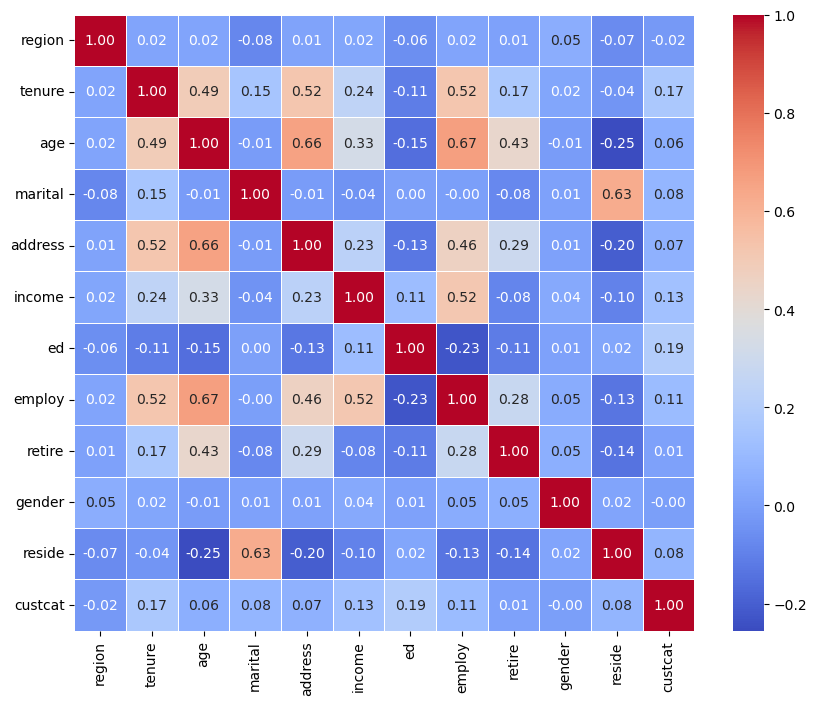

In [8]:
correlation_matrix = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.figure(figsize = (12,6))
sns.heatmap(correlation_mateix, annot = True, cmap = 'coolwarm', fmt = '.2f', linewidths = 0.50

In [11]:
correlation_values = abs(df.corr()['custcat'].drop('custcat')).sort_values(ascending = False)
correlation_values

ed         0.193864
tenure     0.166691
income     0.134525
employ     0.110011
marital    0.083836
reside     0.082022
address    0.067913
age        0.056909
region     0.023771
retire     0.008908
gender     0.004966
Name: custcat, dtype: float64

In [13]:
Cv = abs(df.corr()['custcat'].sort_values(ascending = False))
Cv

custcat    1.000000
ed         0.193864
tenure     0.166691
income     0.134525
employ     0.110011
marital    0.083836
reside     0.082022
address    0.067913
age        0.056909
retire     0.008908
gender     0.004966
region     0.023771
Name: custcat, dtype: float64

In [21]:
X = df.drop('custcat',axis=1)
y = df['custcat']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

k = 3

knn_classifier = KNeighborsClassifier(n_neighbors=k)

knn_model = knn_classifier.fit(
    X_train_scaled,
    y_train
)

knn_predict = knn_model.predict(X_test)

print('KNN PREDICTION:', knn_predict)

KNN PREDICTION: [2 2 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 2 2 2 2 2 2 2 2 3 2 2 2 2 2 2
 2 2 2 1 2 2 2 2 2 2 2 2 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 2 2 2 3 2 2 2 3 2 2 2 2 2 2 2 2 2 2 2 3
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 3 2 3 2 2 2 2 2 2 3]


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


In [24]:
knn_model = knn_classifier.fit(
    X_train_scaled,
    y_train
)
knn_model

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [25]:
print("Test set Accuracy: ", accuracy_score(y_test, knn_predict))

Test set Accuracy:  0.21


In [33]:
X = df.drop('custcat',axis=1)
y = df['custcat']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify  = y)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

k = 6

knn_classifier = KNeighborsClassifier(n_neighbors = k)

knn_model = knn_classifier.fit(X_train_scaled, y_train)

knn_predict = knn_model.predict(X_test)

print('knn_predict', knn_predict)



knn_predict [3 3 4 3 3 2 3 2 3 3 3 3 3 3 3 2 3 3 3 3 2 3 3 3 3 3 3 3 3 3 4 3 2 2 3 3 3
 3 3 3 3 3 3 2 3 3 3 3 3 4 3 3 3 3 3 3 3 2 3 3 3 3 3 3 3 3 2 3 3 3 3 4 3 3
 3 3 3 3 3 3 3 3 3 3 2 3 3 3 3 3 3 3 3 3 4 2 3 2 3 3 3 3 3 3 3 2 3 3 3 3 4
 3 3 3 4 3 3 3 3 4 3 3 3 3 2 3 3 3 3 2 3 2 4 3 3 3 3 3 3 3 3 2 3 3 2 3 3 3
 3 3 3 3 3 3 2 3 3 3 2 3 3 3 3 3 3 3 3 3 3 2 3 3 3 2 3 3 3 3 3 3 3 3 2 3 3
 3 3 2 3 3 4 3 4 3 3 3 3 3 3 4]


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


In [66]:
k = 38

knn_classifier = KNeighborsClassifier(n_neighbors = k)

knn_model = knn_classifier.fit(X_train_scaled, y_train)

knn_predict = knn_model.predict(X_test)

knn_predict



/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3])

In [55]:
accuracy_testt = accuracy_score(y_test, knn_predict)
accuracy

0.28

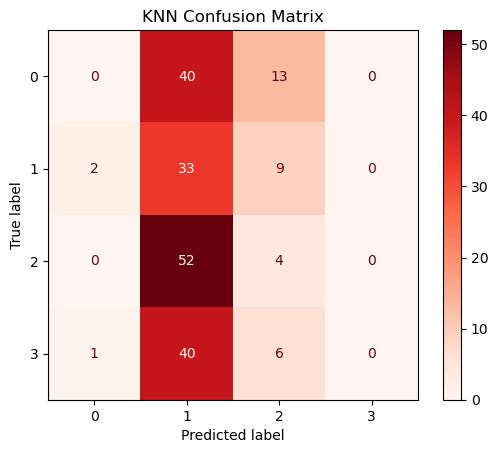

In [63]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, knn_predict)

disp = ConfusionMatrixDisplay(confusion_matrix = cm)
disp.plot(cmap = 'Reds')
plt.title('KNN Confusion Matrix')
plt.show()

In [56]:
prediction_counts = pd.Series(knn_predict).value_counts().sort_index()
prediction_counts

1      3
2    165
3     32
Name: count, dtype: int64

In [46]:
accuracy =  accuracy_score(y_test, knn_predict)
accuracy

0.28

In [36]:
import pandas as pd

prediction_counts = pd.Series(knn_predict).value_counts().sort_index()

print(prediction_counts)

2     24
3    164
4     12
Name: count, dtype: int64


In [37]:
import numpy as np

unique_classes, counts = np.unique(knn_predict, return_counts=True)

print(dict(zip(unique_classes, counts)))

{np.int64(2): np.int64(24), np.int64(3): np.int64(164), np.int64(4): np.int64(12)}


In [38]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, knn_predict)

print("Test set Accuracy:", accuracy)

Test set Accuracy: 0.32


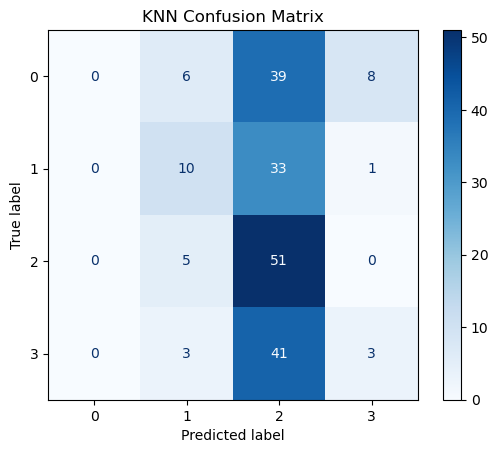

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, knn_predict)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.title("KNN Confusion Matrix")
plt.show()



In [40]:
print("Actual categories:")
print(y_test.value_counts().sort_index())

print("\nPredicted categories:")
print(pd.Series(knn_predict).value_counts().sort_index())

Actual categories:
custcat
1    53
2    44
3    56
4    47
Name: count, dtype: int64

Predicted categories:
2     24
3    164
4     12
Name: count, dtype: int64


In [35]:
Ks = 10
acc = np.zeros((Ks))
std_acc = np.zeros((Ks))
for n in range(1,Ks+1):
    #Train Model and Predict  
    knn_model_n = KNeighborsClassifier(n_neighbors = n).fit(X_train,y_train)
    yhat = knn_model_n.predict(X_test)
    acc[n-1] = accuracy_score(y_test, yhat)
    std_acc[n-1] = np.std(yhat==y_test)/np.sqrt(yhat.shape[0])
print(std_acc[n-1])

0.032846232660687286


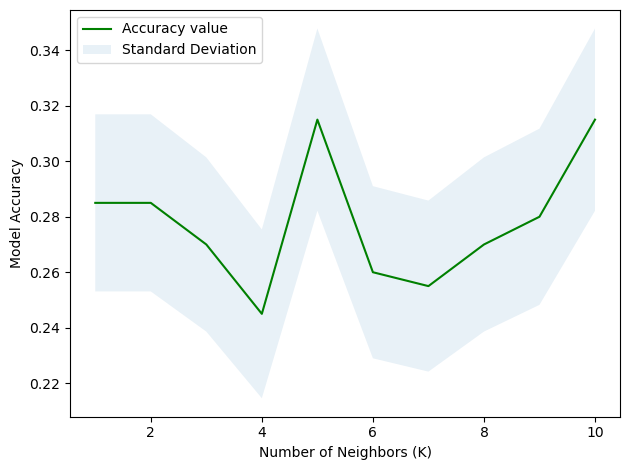

In [42]:
plt.plot(range(1,Ks+1),acc,'g')
plt.fill_between(range(1,Ks+1),acc - 1 * std_acc,acc + 1 * std_acc, alpha=0.10)
plt.legend(('Accuracy value', 'Standard Deviation'))
plt.ylabel('Model Accuracy')
plt.xlabel('Number of Neighbors (K)')
plt.tight_layout()
plt.show()

